Universidad del Valle de Guatemala  
Departamento de Ciencias de la Computación  
CC2017 Modelación y Simulación

# 06. Venta a crédito y morosidad

Algunos negocios venden a crédito, por ejemplo una cafetería que lleva cuenta a las oficinas cercanas y les cobra a fin de mes. Vender a crédito puede atraer clientes, pero el dinero llega después y una parte nunca llega. En este notebook se agrega ese efecto con dos paradigmas.

- En la dinámica de sistemas se agrega el stock de cuentas por cobrar. Las ventas a crédito lo llenan y lo vacían los cobros y los incobrables.
- En los agentes, cada cliente a crédito tiene su propia probabilidad de caer en mora. Quien cae en mora no paga sus compras del mes, pierde el crédito y puede dejar el negocio.

## 1. Parámetros

El escenario es ilustrativo. El 20 % de los clientes compra a crédito, se cobra un mes después, la mora mensual promedio es de 5 % y la mitad de quienes caen en mora deja el negocio.

In [1]:
import sys
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../src")
from business_sim.model import simulate_business
from business_sim.montecarlo import run_montecarlo
from business_sim.params import BusinessParams, CreditParams, CustomerParams, QueueParams
from business_sim.queue_des import loss_table

p, cp, qp = BusinessParams(), CustomerParams(), QueueParams()
tabla = loss_table(qp, list(range(0, 201, 10)), [1, 2, 3, 4], days=60, seed=5)
credito = CreditParams(credit_share=0.2, payment_delay=1, mean_default=0.05, default_churn=0.5)
pd.Series(vars(credito)).to_frame("Valor")

,Valor
credit_share,0.20
payment_delay,1.00
mean_default,0.05
default_concentration,20.00
default_churn,0.50


## 2. Una corrida con y sin crédito

Las dos corridas usan la misma semilla. Primero se verifica que todo lo vendido a crédito se cobre, sea incobrable o siga pendiente.

Ventas a crédito - cobros - incobrables - saldo final por cobrar = -0.000000


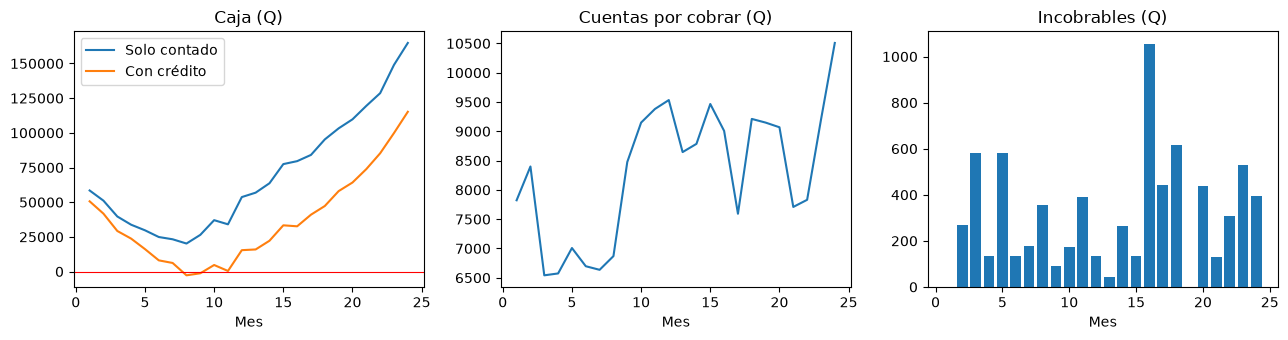

,Solo contado,Con crédito
Caja mínima (Q),20185.0,-2735.0
Caja final (Q),164811.0,115187.0
Ventas a crédito (Q),0.0,199255.0
Incobrables (Q),0.0,7374.0
Clientes que cayeron en mora,0.0,65.0
Clientes activos mes 24,751.0,763.0


In [2]:
sin = simulate_business(p, cp, qp, tabla, rng=1, noise=0.05)
con = simulate_business(p, cp, qp, tabla, rng=1, noise=0.05, crp=credito)

balance = con["credit_sales"].sum() - con["collected"].sum() - con["bad_debt"].sum() - con["receivables"].iloc[-1]
print(f"Ventas a crédito - cobros - incobrables - saldo final por cobrar = {balance:.6f}")

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.5))
ejes[0].plot(sin.index, sin["cash"], label="Solo contado")
ejes[0].plot(con.index, con["cash"], label="Con crédito")
ejes[0].axhline(0, color="red", lw=0.8)
ejes[0].set_title("Caja (Q)")
ejes[0].legend()
ejes[1].plot(con.index, con["receivables"])
ejes[1].set_title("Cuentas por cobrar (Q)")
ejes[2].bar(con.index, con["bad_debt"])
ejes[2].set_title("Incobrables (Q)")
for eje in ejes:
    eje.set_xlabel("Mes")
plt.tight_layout()
plt.show()

pd.DataFrame({
    nombre: {
        "Caja mínima (Q)": df["cash"].min(),
        "Caja final (Q)": df["cash"].iloc[-1],
        "Ventas a crédito (Q)": df["credit_sales"].sum(),
        "Incobrables (Q)": df["bad_debt"].sum(),
        "Clientes que cayeron en mora": df["defaulters"].sum(),
        "Clientes activos mes 24": df["active"].iloc[-1],
    }
    for nombre, df in {"Solo contado": sin, "Con crédito": con}.items()
}).round(0)

La diferencia contable es cero, por lo que el stock de cuentas por cobrar conserva el dinero. Las cuentas por cobrar se mantienen entre Q6 500 y Q10 500 porque cada mes se cobra lo vendido el mes anterior. En 24 meses se venden Q199 255 a crédito, Q7 374 resultan incobrables y 65 clientes caen en mora.

Con crédito la caja mínima pasa de Q20 185 a -Q2 735, es decir que en esta corrida el negocio se queda sin caja por un momento, y la caja final baja de Q164 811 a Q115 187. La baja es mayor que los incobrables porque una parte del dinero queda retenida en cuentas por cobrar, parte de los clientes en mora deja el negocio y, desde ese momento, la corrida sigue un camino aleatorio distinto.

## 3. Monte Carlo con y sin crédito

Se simulan 500 escenarios en cada caso con las mismas semillas.

In [3]:
N = 500
r_sin, _ = run_montecarlo(N, p, cp, qp, tabla, seed=1)
r_con, _ = run_montecarlo(N, p, cp, qp, tabla, seed=1, crp=credito)
pd.DataFrame({
    nombre: {
        "Probabilidad de llegar al mes 24": r["survived"].mean(),
        "Caja final P50 (Q)": r["final_cash"].median(),
        "Incobrables P50 (Q)": r["bad_debt"].median(),
        "Incobrables P90 (Q)": r["bad_debt"].quantile(0.9),
    }
    for nombre, r in {"Solo contado": r_sin, "Con crédito": r_con}.items()
}).round(3)

,Solo contado,Con crédito
Probabilidad de llegar al mes 24,0.672,0.552
Caja final P50 (Q),136501.751,109016.071
Incobrables P50 (Q),0.000,7119.075
Incobrables P90 (Q),0.000,9517.091


Con 500 escenarios la probabilidad de llegar al mes 24 baja de 67.2 % a 55.2 % al vender a crédito. La caja final mediana baja de Q136 502 a Q109 016. Los incobrables acumulados son de Q7 119 en la mediana y de Q9 517 en el percentil 90.

## 4. ¿Hasta qué morosidad aguanta el negocio?

Se varía la mora mensual promedio con 20 % y 40 % de clientes a crédito, con 300 escenarios por punto. Con mora de 0 % solo actúa el retraso del cobro.

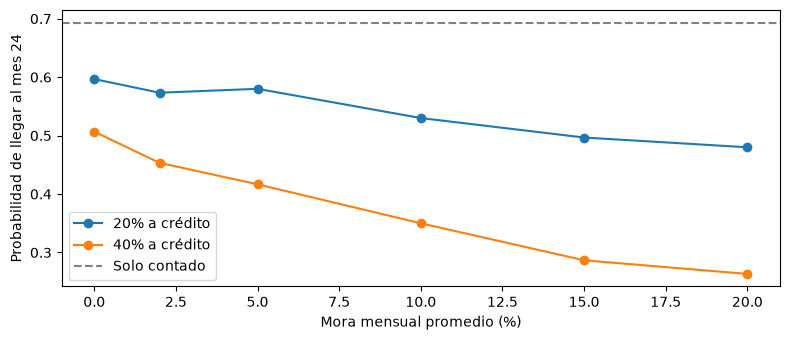

Solo contado = 0.693


,20% a crédito,40% a crédito
Mora mensual,,
0.00,0.597,0.507
0.02,0.573,0.453
0.05,0.580,0.417
0.10,0.530,0.350
0.15,0.497,0.287
0.20,0.480,0.263


In [4]:
moras = [0.0, 0.02, 0.05, 0.10, 0.15, 0.20]
curvas = {}
for fraccion in [0.2, 0.4]:
    curvas[f"{fraccion:.0%} a crédito"] = [
        run_montecarlo(300, p, cp, qp, tabla, seed=1, crp=replace(credito, credit_share=fraccion, mean_default=m))[0]["survived"].mean()
        for m in moras
    ]
base = run_montecarlo(300, p, cp, qp, tabla, seed=1)[0]["survived"].mean()

plt.figure(figsize=(8, 3.5))
for nombre, valores in curvas.items():
    plt.plot([m * 100 for m in moras], valores, marker="o", label=nombre)
plt.axhline(base, color="gray", ls="--", label="Solo contado")
plt.xlabel("Mora mensual promedio (%)")
plt.ylabel("Probabilidad de llegar al mes 24")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Solo contado = {base:.3f}")
pd.DataFrame(curvas, index=pd.Index(moras, name="Mora mensual")).round(3)

Con mora de 0 % la probabilidad ya cae de 69.3 % (solo contado) a 59.7 % con 20 % a crédito y a 50.7 % con 40 % a crédito. Esa caída se debe solo a que el dinero llega un mes después. Con mora de 20 % la probabilidad baja a 48.0 % y 26.3 %. El efecto de la mora crece con la fracción vendida a crédito. Con 20 % a crédito, los valores entre 2 % y 5 % de mora son casi iguales por el ruido de 300 escenarios.

## 5. Efecto del plazo de cobro

Se cambia el plazo con 20 % de clientes a crédito y mora de 5 %.

In [5]:
pd.DataFrame({
    "Probabilidad de llegar al mes 24": [
        run_montecarlo(300, p, cp, qp, tabla, seed=1, crp=replace(credito, payment_delay=d))[0]["survived"].mean()
        for d in [1, 2, 3]
    ]
}, index=pd.Index([1, 2, 3], name="Meses de plazo")).round(3)

,Probabilidad de llegar al mes 24
Meses de plazo,
1,0.580
2,0.490
3,0.403


Cada mes adicional de plazo baja la probabilidad de llegar al mes 24, de 58.0 % con 1 mes a 49.0 % con 2 y a 40.3 % con 3.

## Conclusión

Para esta cafetería vender a crédito aumenta el riesgo de quedarse sin caja aunque la mora sea baja, porque el retraso del cobro pesa tanto como los incobrables en los primeros meses. Si se ofrece crédito, conviene limitarlo a una fracción pequeña de clientes y cobrar en el menor plazo posible.